# 2. O M2 é a inflação de verdade?

O notebook anterior mostrou que a conta do texto fecha: depois de 2008, a Selic e o Ibovespa renderam menos do que
o M2 cresceu. O passo seguinte do texto é chamar essa diferença de **juro real negativo**, porque "a inflação real
não é expressa por índices de aumento de preços - e sim pelo aumento da base monetária".

Este notebook testa essa régua. Três perguntas:

1. O M2 é a base monetária?
2. Do que o M2 é feito, e por que ele cresce?
3. Quem "perdeu para o M2" ficou mais pobre em quê?

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from juros_negativos import analise, estilo
from juros_negativos.caminhos import TRATADOS
from juros_negativos.estilo import br, pct

estilo.aplicar()

brasil = pd.read_parquet(TRATADOS / "brasil.parquet")
mensal = brasil.set_index("data")
niveis = analise.niveis_do_brasil(brasil)

INICIO = "2008-01"
FIM = niveis.index[-1] + pd.DateOffset(months=1)  # abertura do mês seguinte ao último dado
MESES = analise.meses_entre(INICIO, FIM)
print(f"Período: da abertura de jan/2008 ao fim de {niveis.index[-1]:%m/%Y} ({MESES} meses)")

Período: da abertura de jan/2008 ao fim de 08/2026 (224 meses)


## As réguas possíveis

"Quanto o dinheiro cresceu" tem várias respostas, porque há várias definições de dinheiro:

- **Base monetária**: o que o Banco Central emite. Cédulas e moedas, mais as reservas que os bancos mantêm nele.
- **M1**: o dinheiro que circula. Cédulas e moedas com o público, mais os depósitos à vista (conta-corrente).
- **M2**: o M1 mais a poupança e os títulos emitidos pelos bancos (CDBs, LCIs, LCAs e parecidos).
- **M3**: o M2 mais as cotas de fundos de renda fixa e as operações compromissadas.
- **M4**: o M3 mais os títulos públicos em poder do público.

Do M1 para cima, a conta deixa de ser "dinheiro" no sentido de cédula e passa a ser a soma das aplicações
financeiras do país. E há duas réguas que não são de dinheiro: os **preços** (IPCA) e o **PIB nominal**, que é a
soma de tudo o que o país produziu, a preços correntes.

O gráfico compara a Selic com cada uma desde 2008. Ela ganha dos preços, do PIB nominal, da base monetária e do
M1. Só perde dos três agregados amplos, justamente os que são formados por aplicações que rendem juros.

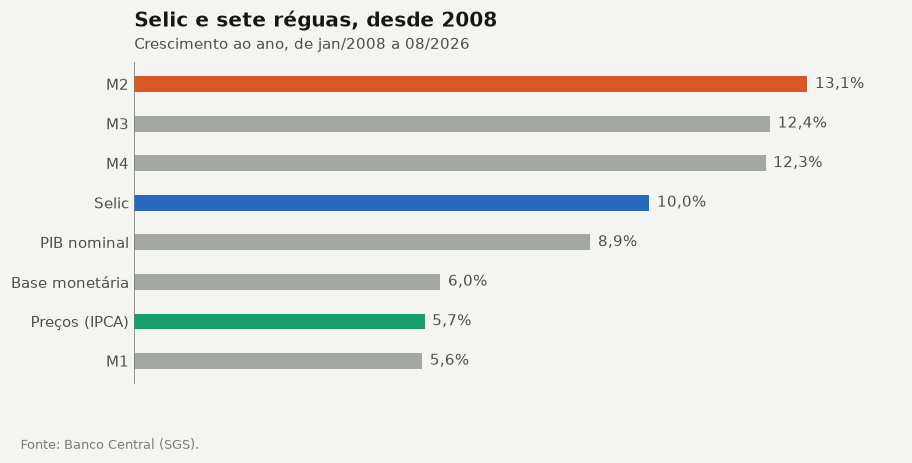

Selic acima de cada régua, ao ano:
  Preços (IPCA)    +4,1%
  PIB nominal      +1,1%
  Base monetária   +3,8%
  M1               +4,2%
  M2               −2,7%
  M3               −2,1%
  M4               −2,0%


In [2]:
variacoes = analise.variacao(niveis, INICIO, FIM)
ao_ano = analise.anualizar(variacoes, MESES)

NOMES = {"selic": "Selic"} | analise.REGUAS
taxas = ao_ano[list(NOMES)].rename(NOMES).sort_values(ascending=False)
cores = [estilo.AZUL if nome == "Selic" else estilo.cor({v: k for k, v in NOMES.items()}[nome]) for nome in taxas.index]

fig, ax = plt.subplots(figsize=(9, 3.8))
estilo.barras(ax, taxas, cores, lambda v: pct(v, 1))
estilo.titulo(ax, "Selic e sete réguas, desde 2008", f"Crescimento ao ano, de jan/2008 a {niveis.index[-1]:%m/%Y}")
estilo.fonte(fig, "Fonte: Banco Central (SGS).")
plt.show()

acima = analise.anualizar(analise.descontar(variacoes["selic"], variacoes[list(analise.REGUAS)]), MESES)
print("Selic acima de cada régua, ao ano:")
for regua, nome in analise.REGUAS.items():
    print(f"  {nome:<16} {pct(acima[regua], 1, sinal=True)}")

## A base monetária não é o M2

O texto usa "base monetária" para falar do M1 e do M2. São coisas diferentes, e a diferença decide a conta.

A base monetária, o dinheiro que o Banco Central de fato emite, cresceu 6,0% ao ano desde 2008, quase o mesmo que
os preços (5,7%). Como fração da economia, ela **encolheu**: de 5,4% para 3,2% do PIB. Se "inflação é o aumento
da base monetária", então por essa definição a Selic rendeu 3,8% ao ano acima da inflação.

O M2 fez o caminho oposto: de 29% para 58% do PIB.

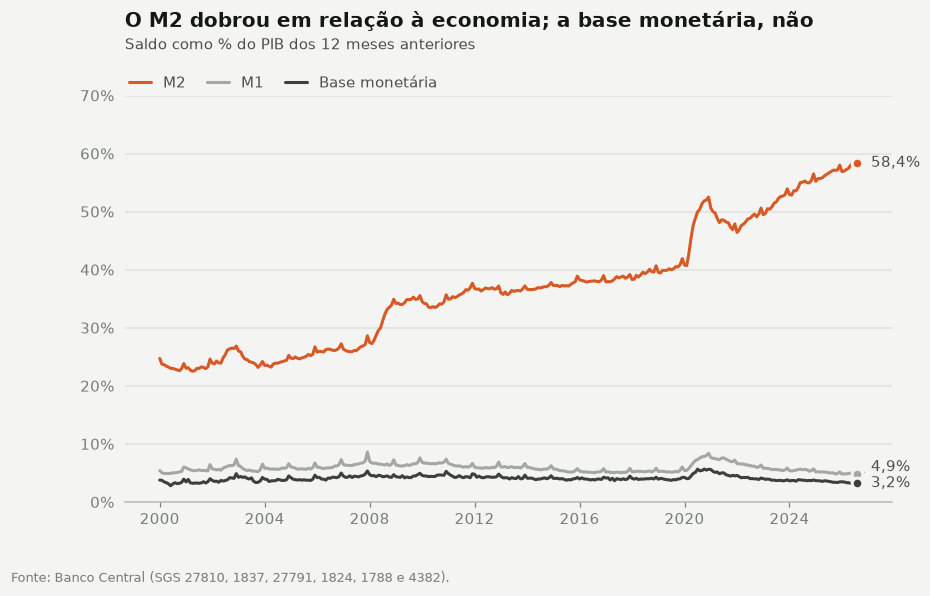

12/2007: M2 28,7%, M1 8,6%, Base monetária 5,4%
08/2026: M2 58,4%, M1 4,9%, Base monetária 3,2%


In [3]:
desde_2000 = mensal.loc["2000-01-01":]
sobre_o_pib = pd.DataFrame(
    {
        "M2": desde_2000["m2"] / desde_2000["pib_12m"],
        "M1": desde_2000["m1"] / desde_2000["pib_12m"],
        "Base monetária": desde_2000["base_monetaria"] / desde_2000["pib_12m"],
    }
)

fig, ax = plt.subplots()
ax.plot(sobre_o_pib["M2"], color=estilo.LARANJA, label="M2")
ax.plot(sobre_o_pib["M1"], color=estilo.CINZA, label="M1")
ax.plot(sobre_o_pib["Base monetária"], color=estilo.GRAFITE, label="Base monetária")
estilo.titulo(
    ax,
    "O M2 dobrou em relação à economia; a base monetária, não",
    "Saldo como % do PIB dos 12 meses anteriores",
    legenda=True,
)
estilo.eixo_pct(ax.yaxis)
ax.set_ylim(0, 0.7)
estilo.rotular_fins(ax, lambda v: pct(v, 1))
estilo.fonte(fig, "Fonte: Banco Central (SGS 27810, 1837, 27791, 1824, 1788 e 4382).")
plt.show()

for mes in ["2007-12-01", mensal.index[-1]]:
    print(
        f"{pd.Timestamp(mes):%m/%Y}: "
        + ", ".join(f"{nome} {pct(sobre_o_pib.loc[mes, nome], 1)}" for nome in sobre_o_pib)
    )

## Quase todo o M2 rende juros

A parte do M2 que não é M1 (poupança, CDBs e outros títulos de bancos) paga juros a quem a tem. Em 2007 ela era
70% do M2. Hoje é 92%.

Isso muda o sentido da comparação. Quando o juro de um CDB é creditado, o saldo cresce, e o M2 cresce junto.
Quando alguém faz um depósito novo, também. O crescimento do M2 é, em boa parte, a soma dos juros que as
aplicações renderam com o dinheiro novo que entrou nelas. Uma aplicação sozinha, sem aportes, só tem a primeira
parte: ela fica para trás do total sempre que entra dinheiro novo no sistema.

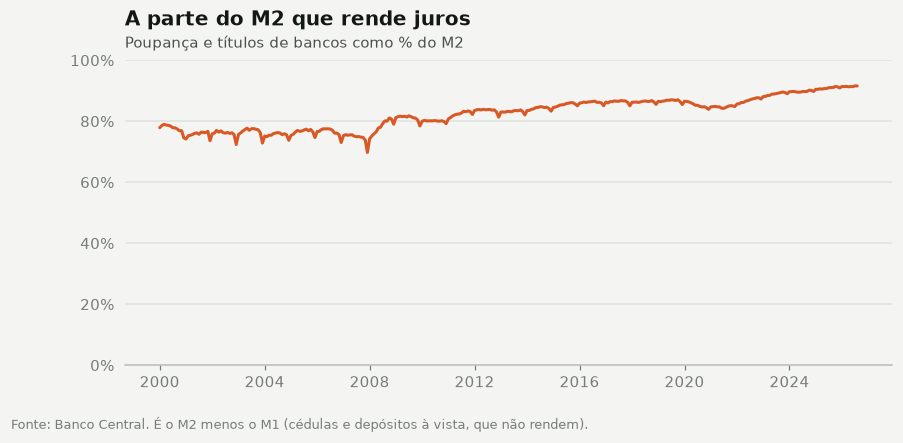

Em 12/2007: 69,8%; em 08/2026: 91,6%


In [4]:
remunerado = analise.participacao_remunerada_do_m2(brasil).loc["2000-01-01":]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(remunerado, color=estilo.LARANJA)
estilo.titulo(ax, "A parte do M2 que rende juros", "Poupança e títulos de bancos como % do M2")
estilo.eixo_pct(ax.yaxis)
ax.set_ylim(0, 1)
estilo.rotular_fins(ax, lambda v: pct(v))
estilo.fonte(fig, "Fonte: Banco Central. É o M2 menos o M1 (cédulas e depósitos à vista, que não rendem).")
plt.show()

print(f"Em 12/2007: {pct(remunerado['2007-12-01'], 1)}; em {remunerado.index[-1]:%m/%Y}: {pct(remunerado.iloc[-1], 1)}")

## De onde vem o crescimento do M2

O M2 pode ser escrito como um produto de três partes:

**M2 = preços × (PIB ÷ preços) × (M2 ÷ PIB)**

A primeira é a inflação. A segunda, o crescimento da economia acima dos preços. A terceira, o quanto as pessoas e
empresas guardam em bancos em relação ao tamanho da economia. Dos 13,1% ao ano que o M2 cresceu desde 2008, 5,7
pontos são inflação, 3,1 são crescimento da economia e 3,9 são o aumento do dinheiro guardado.

Tratar os 13,1% como "a inflação de verdade" é chamar de inflação também o crescimento do país e a decisão das
pessoas de poupar em CDB.

(A segunda parte usa o IPCA, e não o deflator do PIB, para descontar os preços. Com o deflator, o crescimento
real do PIB no período é menor, perto de 2% ao ano, e a diferença vai para a primeira parcela.)

In [5]:
linhas = []
for inicio, fim in [("1996-01", "2008-01"), ("2008-01", "2018-01"), ("2018-01", FIM), ("2008-01", FIM)]:
    partes = analise.anualizar(analise.decompor_m2(brasil, inicio, fim), analise.meses_entre(inicio, fim))
    linhas.append(
        {
            "período": f"jan/{str(inicio)[:4]} a {pd.Timestamp(fim) - pd.DateOffset(months=1):%m/%Y}",
            "M2 ao ano": pct(partes["m2"], 1),
            "preços": pct(partes["precos"], 1),
            "economia acima dos preços": pct(partes["pib_real"], 1),
            "M2 ÷ PIB": pct(partes["m2_sobre_pib"], 1, sinal=True),
        }
    )
pd.DataFrame(linhas).set_index("período")

,M2 ao ano,preços,economia acima dos preços,M2 ÷ PIB
período,,,,
jan/1996 a 12/2007,"13,0%","6,8%","4,8%","+1,0%"
jan/2008 a 12/2017,"12,7%","6,1%","3,0%","+3,2%"
jan/2018 a 08/2026,"13,6%","5,2%","3,1%","+4,7%"
jan/2008 a 08/2026,"13,1%","5,7%","3,1%","+3,9%"


## Os saltos do M2 não são só emissão

O M2 deu dois saltos: 39% em 2008 e 29% em 2020. Vale olhar o que aconteceu com os outros agregados nos mesmos
anos.

Em **2008**, a base monetária ficou parada (+0,6%) e o M1 caiu. O M4, que soma tudo, cresceu 18,5%, perto do que
vinha crescendo. O salto do M2 foi uma troca de gaveta: na crise, o dinheiro saiu dos fundos (que estão no M3 e no
M4) e foi para CDBs de bancos grandes (que estão no M2). Nenhum real novo foi emitido para isso.

Em **2020** houve emissão de fato: a base cresceu 36%, com o auxílio emergencial e a procura por dinheiro vivo. Em
2021 ela recuou 5%.

Uma régua de inflação que sobe 39% quando as pessoas trocam de aplicação não está medindo inflação.

In [6]:
dezembros = niveis[niveis.index.month == 12]
anual = (dezembros / dezembros.shift(1) - 1)[["selic", "ipca", "base_monetaria", "m1", "m2", "m3", "m4"]]
anual.index = anual.index.year
anual.loc[[2007, 2008, 2009, 2019, 2020, 2021]].map(lambda v: pct(v, 1, sinal=True))

,selic,ipca,base_monetaria,m1,m2,m3,m4
data,,,,,,,
2007,"+11,8%","+4,5%","+21,1%","+32,9%","+18,6%","+17,1%","+21,4%"
2008,"+12,5%","+5,9%","+0,6%","−3,4%","+39,4%","+18,4%","+18,5%"
2009,"+9,9%","+4,3%","+12,6%","+12,1%","+9,1%","+15,9%","+15,4%"
2019,"+5,9%","+4,3%","+4,8%","+9,1%","+8,7%","+7,7%","+7,3%"
2020,"+2,8%","+4,5%","+36,3%","+43,2%","+29,0%","+17,9%","+16,4%"
2021,"+4,4%","+10,1%","−5,2%","+1,9%","+8,1%","+9,7%","+13,1%"


## A mesma Selic, quatro réguas

R$ 100 aplicados na Selic em janeiro de 2008 e medidos de quatro jeitos. Por três deles o dinheiro cresceu: 214
descontando os preços, 202 descontando a base monetária e 122 descontando o PIB nominal, que é a mais exigente
das três, porque exige acompanhar também o crescimento da economia. Só pelo M2 o resultado fica abaixo de 100:
60.

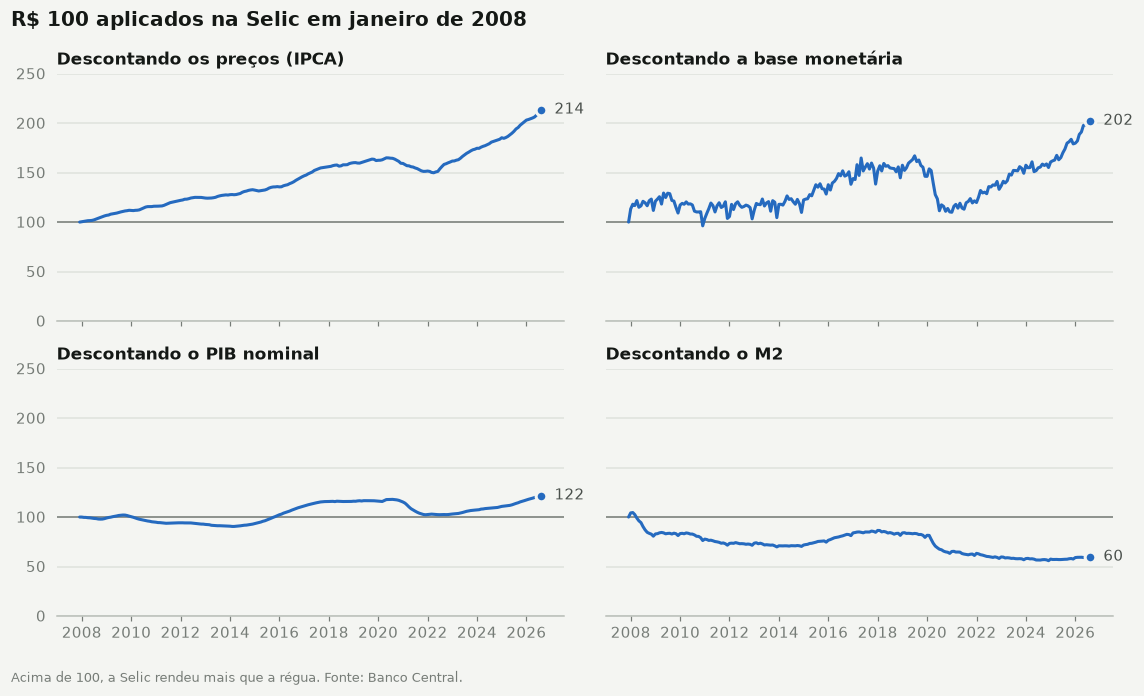

In [7]:
QUATRO = {"ipca": "os preços (IPCA)", "base_monetaria": "a base monetária", "pib": "o PIB nominal", "m2": "o M2"}
periodo = niveis.loc[pd.Timestamp(INICIO) - pd.DateOffset(months=1) :]

fig, eixos = plt.subplots(2, 2, figsize=(10.5, 6), sharex=True, sharey=True)
for ax, (regua, nome) in zip(eixos.flat, QUATRO.items()):
    indice = periodo["selic"] / periodo[regua]
    indice = 100 * indice / indice.iloc[0]
    ax.plot(indice, color=estilo.AZUL, label="Selic")
    estilo.linha_de_base(ax, 100)
    ax.set_title(f"Descontando {nome}", loc="left", fontsize=11, fontweight="bold")
    ax.set_ylim(0, 250)
    estilo.rotular_fins(ax, lambda v: br(v))
fig.suptitle("R$ 100 aplicados na Selic em janeiro de 2008", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
estilo.fonte(fig, "Acima de 100, a Selic rendeu mais que a régua. Fonte: Banco Central.")
plt.show()

## O que a Selic compra

A pergunta que interessa a quem poupa não é "qual a minha fatia do M2", e sim "o que o meu dinheiro compra". Os
mesmos R$ 100, com os juros, compram hoje, em relação ao que compravam em janeiro de 2008:

- 114% mais da cesta de consumo do IPCA;
- 115% mais ações (Ibovespa) e 104% mais dólares;
- 46% mais imóveis (pelo índice IVG-R do Banco Central) e 40% mais salários mínimos;
- uma fatia 22% maior do PIB;
- 62% menos ouro, e uma fatia 40% menor do M2.

Pela régua do M2, quem aplicou na Selic ficou 40% mais pobre no mesmo período em que passou a comprar mais de
quase tudo.

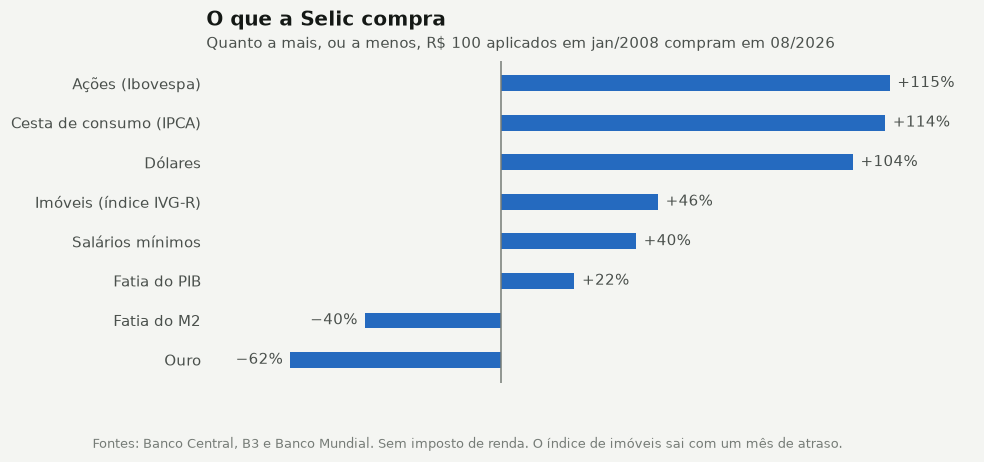

In [8]:
compras = analise.poder_de_compra(niveis, "selic", INICIO, FIM).rename(analise.COMPRAS).sort_values(ascending=False) - 1

fig, ax = plt.subplots(figsize=(9, 3.8))
estilo.barras(ax, compras, estilo.AZUL, lambda v: pct(v, sinal=True))
estilo.titulo(
    ax,
    "O que a Selic compra",
    f"Quanto a mais, ou a menos, R$ 100 aplicados em jan/2008 compram em {niveis.index[-1]:%m/%Y}",
)
estilo.fonte(
    fig,
    "Fontes: Banco Central, B3 e Banco Mundial. Sem imposto de renda. O índice de imóveis sai com um mês de atraso.",
)
plt.show()

## O que fica deste notebook

1. **O M2 não é a base monetária.** A base, que é o dinheiro que o Banco Central emite, cresceu no ritmo dos
   preços desde 2008 e encolheu em relação ao PIB. Pela definição que o próprio texto dá ("aumento da base
   monetária"), a Selic ganhou da inflação.
2. **O M2 é quase todo feito de aplicações que rendem juros**: 92% dele. Ele cresce com os juros creditados e com
   o dinheiro novo que entra nos bancos.
3. **O M2 dobrou em relação ao PIB** (de 29% para 58%). Dos 13,1% ao ano que cresceu, só 5,7 pontos são preços.
4. **A Selic só perde para os agregados amplos** (M2, M3 e M4). Ganha dos preços, do PIB nominal, da base
   monetária e do M1.
5. **A leitura generosa do argumento continua valendo**: quem rende menos que o M2 perde participação no total
   das aplicações do país. Isso é um fato sobre participação, não sobre poder de compra, e não é o que se entende
   por "juro negativo".